# Results_Paper · every figure and table of the paper from the stored results

This notebook rebuilds **all the data figures and tables of the paper** (*MIL-CREDA*, IJNS submission) from the summaries that the stage notebooks `01`–`06` stored under `MIL-CREDA-EEG/Results/paper/<stage>/summary/`. It trains nothing and downloads nothing: it runs in about a minute on any CPU.

It then compares every number the paper states in the text and tables with the value recomputed from those summaries (tolerance 0 on the printed digits, unless a row says otherwise).

| Paper item | Stage notebook that produced its summary |
|---|---|
| Table `tab:selection-dev`, Figure `fig:synthetic-map` | `02_Synthetic_Criteria_Pool.ipynb` |
| Tables `tab:synthetic-attention-variants`, `tab:synthetic-term-ablation`; Figures `fig:synthetic-attention-signal`, `fig:synthetic-alignment` | `03_Synthetic_Mechanisms.ipynb` |
| Table `tab:ieee-ranking` | `04_ADHD_Pool.ipynb` |
| Table `tab:ieee-best-subject`, Figure `fig:ieee-alignment` | `05_Attention_Influence.ipynb` |
| Figures `fig:ieee-gsa`, `fig:ieee-pair-descriptors` | `06_ADHD_Graph_Analysis.ipynb` |
| Phase-1 rows of the tables (first phase, source only) | `01_Phase1_Bases.ipynb` |

Figures `fig:mm-proposal-summary` and `fig:setup-pipeline` are TikZ diagrams of the method and of the set-up; they hold no measured number and are not rebuilt here.

To regenerate a summary instead of using the stored one, run its stage notebook (see the repository README); the figures and tables below are then rebuilt from the new summary. Retrained numbers may differ slightly from the paper (different hardware and library builds); the stage notebooks report by how much.

In [1]:
import os, sys
from pathlib import Path

os.environ.setdefault("SOURCE_DATE_EPOCH", "0")   # byte-stable PDFs on every rebuild

# src/ of the repository, from a local checkout or a Kaggle/Colab clone of
# https://github.com/Daprosero/Domain_Adaptation
here = Path.cwd()
if not any((p / "src" / "MIL_CREDA_EEG").exists() for p in (here, *here.parents)):
    target = Path("/kaggle/working" if Path("/kaggle/working").exists() else "/content") / "Domain_Adaptation"
    if not target.exists():
        os.system(f"git clone --depth 1 https://github.com/Daprosero/Domain_Adaptation {target}")
    here = target / "MIL-CREDA-EEG" / "Notebooks"
root = next(p for p in (here, *here.parents) if (p / "src" / "MIL_CREDA_EEG").exists())
sys.path.insert(0, str(root / "src"))

import importlib
from IPython.display import Image, Markdown, display
from MIL_CREDA_EEG import repro

STAGES = {
    "01 phase-1 bases": "stage01_bases",
    "02 synthetic criteria pool": "stage02_criteria",
    "03 synthetic mechanisms": "stage03_mechanisms",
    "04 ADHD pool": "stage04_adhd_pool",
    "05 attention influence": "stage05_influence",
    "06 ADHD graph analysis": "stage06_gsa",
}
modules = {name: importlib.import_module(f"MIL_CREDA_EEG.reproduce.{mod}") for name, mod in STAGES.items()}
print("repository:", root)

repository: /Users/diego/Proyectos/MIL-CREDA/implementations/Domain_Adaptation


## Rebuild the figures and tables

Each stage's `render` reads only its stored summary and writes PDF/PNG figures and LaTeX/CSV tables into `Results/paper/<stage>/{figures,tables}/`.

In [2]:
written = {}
for name, m in modules.items():
    written[name] = m.render()
    print(f"{name}: rendered")

01 phase-1 bases: rendered


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


02 synthetic criteria pool: rendered


03 synthetic mechanisms: rendered
04 ADHD pool: rendered


/Users/diego/Proyectos/MIL-CREDA/implementations/Domain_Adaptation/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


05 attention influence: rendered


06 ADHD graph analysis: rendered


## Tables

The LaTeX of each table, as it appears in the paper (`main.tex`).

In [3]:
for name, m in modules.items():
    tables = sorted((repro.results_dir(m.STAGE) / "tables").glob("*.tex"))
    for t in tables:
        display(Markdown(f"**{name} · `{t.name}`**"))
        print(t.read_text())

**01 phase-1 bases · `phase1_bases.tex`**

% generated by MIL_CREDA_EEG.reproduce.stage01_bases.render from the stored summary
\begin{tabular}{lcccccccccccc}
\toprule
Unit & lr & $\ell_2$ & Width & $\tau$ & Epochs & Cut & BA$_{\mathrm{src}}$ & BA & AUC & $\kappa$ & BA$_{\mathrm{pool}}$ & AUC$_{\mathrm{pool}}$ \\
\midrule
\multicolumn{13}{l}{\textit{Synthetic (24 units)}} \\
d0p6-s0p5-r0 & 2.99e-04 & 7.09e-04 & 128 & 0.020 & 100 & 0.192 & 0.500 & 0.500 & 0.583 & 0.000 & 0.500 & 0.404 \\
d0p6-s1p5-r0 & 2.99e-04 & 7.09e-04 & 128 & 0.020 & 100 & 0.192 & 0.500 & 0.500 & 0.444 & 0.000 & 0.500 & 0.410 \\
d0p6-s3-r0 & 2.99e-04 & 7.09e-04 & 128 & 0.020 & 100 & 0.192 & 0.500 & 0.500 & 0.194 & 0.000 & 0.500 & 0.506 \\
d0p6-s0p5-r1 & 4.33e-04 & 1.26e-02 & 64 & 0.191 & 100 & 0.903 & 0.417 & 0.583 & 0.667 & 0.167 & 0.483 & 0.537 \\
d0p6-s1p5-r1 & 4.33e-04 & 1.26e-02 & 64 & 0.191 & 100 & 0.903 & 0.417 & 0.667 & 0.694 & 0.333 & 0.525 & 0.580 \\
d0p6-s3-r1 & 4.33e-04 & 1.26e-02 & 64 & 0.191 & 100 & 0.903 & 0.417 & 0.500 & 0.722 & 0.000 & 0.500 

**02 synthetic criteria pool · `selection-dev.tex`**

\begin{table*}[!t]
\centering
\footnotesize
\caption{Selection criteria (rows) and methods (columns) on the synthetic pool: BA of the picked configuration, mean over 24 units. $p_{\mathrm{Holm}}$ / $\delta$: against cef (criteria) and against MIL-CREDA (methods). Bold: best per column.}
\label{tab:selection-dev}
\setlength{\tabcolsep}{1.5pt}
\begin{tabular*}{\linewidth}{@{\extracolsep{\fill}}lcccccccccccc}
\toprule
Criterion & \shortstack{MIL-\\CREDA} & \shortstack{UDA-\\DDA} & \shortstack{CCA-\\LSC} & CASUAL & COT & \shortstack{CS+\\CCS} & CLUST & CLUDA & \shortstack{Phase\\1} & \shortstack{Mean\\BA} & \shortstack{$p_{\mathrm{Holm}}$ / $\delta$\\(criterion)} & \shortstack{Mean\\rank} \\
\midrule
cef & \textbf{0.721} & 0.707 & 0.666 & \textbf{0.700} & \textbf{0.688} & 0.688 & \textbf{0.684} & \textbf{0.655} & 0.576 & \textbf{0.689} & -- & \textbf{4.71} \\
Centroid score & 0.719 & 0.653 & \textbf{0.670} & 0.658 & 0.645 & \textbf{0.690} & 0.637 & 0.605 &  & 0.660 & 0.079 / +0.03 & 4.88 \

**03 synthetic mechanisms · `synthetic-attention-variants.tex`**

\begin{tabular*}{\columnwidth}{@{\extracolsep{\fill}}lccccc}
\toprule
Aggregation & BA & $p_{\mathrm{Holm}}$/$\delta$ & Rank & \shortstack{Artif.\\AUC} & \shortstack{Event\\AUC} \\
\midrule
Rel.\ + consensus & \textbf{0.72} & ref. & \textbf{2.71} & \textbf{0.57}$^{*}$ & 0.63$^{*}$ \\
Relevance only & 0.71 & 0.31/+0.04 & 3.17 & 0.53 & \textbf{0.65}$^{*}$ \\
Attention (Ilse) & 0.70 & 0.61/+0.01 & 3.21 & 0.52 & 0.62$^{*}$ \\
Gated (Ilse) & 0.69 & 0.61/+0.03 & 3.15 & 0.54 & 0.62$^{*}$ \\
Mean & 0.52 & 0.01/+0.38 & 4.60 & -- & -- \\
Sum & 0.52 & 0.02/+0.33 & 4.17 & -- & -- \\
\bottomrule
\end{tabular*}



... (6 outputs left out)

**06 ADHD graph analysis · `gsa_xgb.tex`**

\begin{tabular}{lrrrrr}
\hline
Window set & BA & AUC & $\Delta$BA vs all & 95\,\% CI & $p_{\mathrm{Holm}}$ \\
\hline
All windows (raw EEG) & 0.645 & 0.672 & -- & -- & -- \\
Highest-attention 25 \% & 0.727 & 0.780 & 0.083 & [0.008, 0.158] & 0.107 \\
Lowest-attention 25 \% & 0.595 & 0.582 & -0.050 & [-0.133, 0.033] & 0.442 \\
Random 25 \% (10 draws) & 0.686 & 0.751 & 0.041 & [-0.017, 0.107] & 0.442 \\
\hline
\end{tabular}



**06 ADHD graph analysis · `pair_descriptors.tex`**

\begin{tabular}{lr}
\hline
descriptor correlation of the pair & 0.988 \\
percentile among the unit's pairs & 0.906 \\
mean descriptor correlation of all pairs & 0.973 \\
centrality correlation of the pair & 0.677 \\
centrality percentile among the unit's pairs & 0.828 \\
pairs in the unit & 876 \\
\hline
\end{tabular}



## Figures

**fig:synthetic-map** · `Results/paper/02_synthetic_criteria_pool/figures/synthetic-map-methods.png`

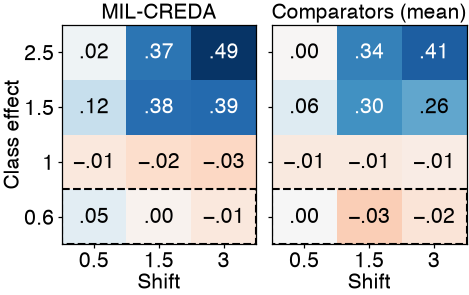

**fig:synthetic-attention-signal** · `Results/paper/03_synthetic_mechanisms/figures/synthetic-attention-signal.png`

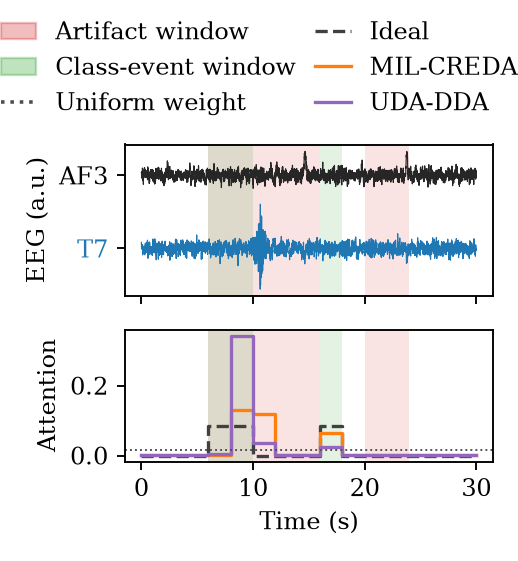

**fig:synthetic-alignment** · `Results/paper/03_synthetic_mechanisms/figures/synthetic-alignment.png`

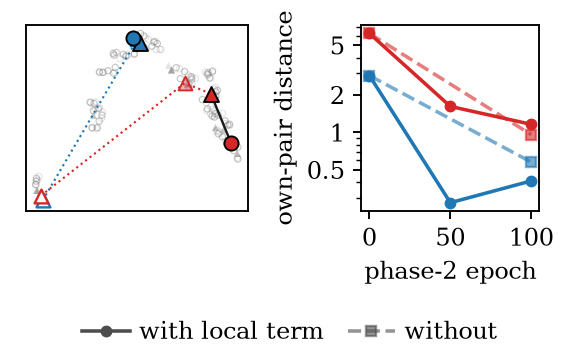

**fig:ieee-gsa** · `Results/paper/06_adhd_graph_analysis/figures/ieee-gsa.png`

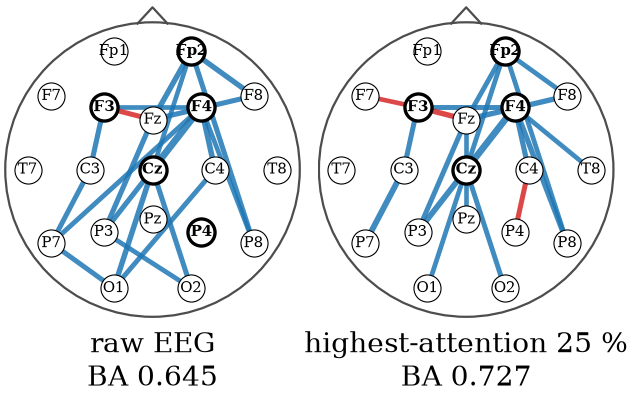

**fig:ieee-alignment** · `Results/paper/05_attention_influence/figures/ieee-alignment.png`

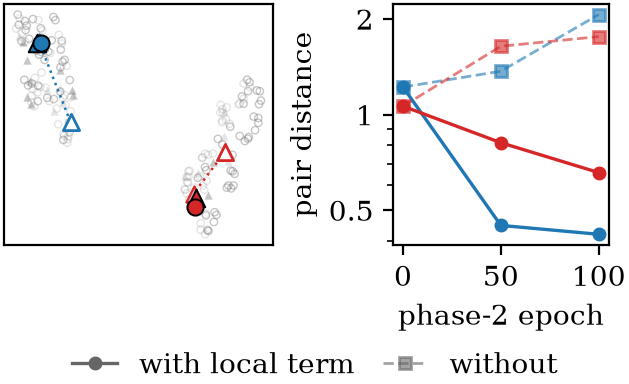

**fig:ieee-pair-descriptors** · `Results/paper/06_adhd_graph_analysis/figures/ieee-pair-descriptors.png`

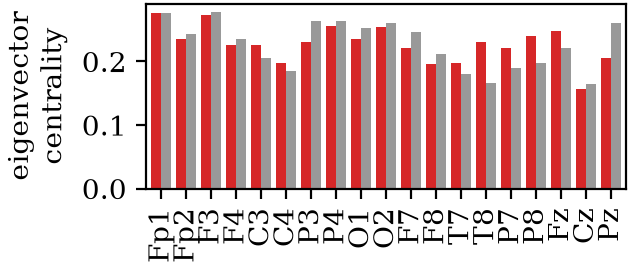

In [4]:
PAPER_FIGURES = [
    ("fig:synthetic-map", "02_synthetic_criteria_pool", "synthetic-map-methods.png"),
    ("fig:synthetic-attention-signal", "03_synthetic_mechanisms", "synthetic-attention-signal.png"),
    ("fig:synthetic-alignment", "03_synthetic_mechanisms", "synthetic-alignment.png"),
    ("fig:ieee-gsa", "06_adhd_graph_analysis", "ieee-gsa.png"),
    ("fig:ieee-alignment", "05_attention_influence", "ieee-alignment.png"),
    ("fig:ieee-pair-descriptors", "06_adhd_graph_analysis", "ieee-pair-descriptors.png"),
]
for label, stage, png in PAPER_FIGURES:
    display(Markdown(f"**{label}** · `Results/paper/{stage}/figures/{png}`"))
    display(Image(filename=str(repro.results_dir(stage) / "figures" / png), width=520))

## Every number of the paper next to the stored results

In [5]:
import csv
all_rows = []
for name, m in modules.items():
    display(Markdown(f"### {name}"))
    rows = repro.compare(m.paper_checks())
    for r in rows:
        all_rows.append({"stage": name, **r})

out = repro.eeg_dir() / "Results" / "paper" / "paper_checks.csv"
with out.open("w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=list(all_rows[0]))
    w.writeheader(); w.writerows(all_rows)
bad = [r for r in all_rows if not r["within"]]
print(f"{len(all_rows) - len(bad)} of {len(all_rows)} paper numbers reproduced; written to {out.relative_to(root)}")
assert not bad, bad

### 01 phase-1 bases

quantity                                                            obtained    paper   within tolerance
synthetic first phase, mean BA over the 24 units (evaluation pool)     0.576    0.576   yes (+/-0)
ADHD Phase 1 (source only), mean BA over the 10 units                  0.655    0.655   yes (+/-0)
ADHD Phase 1 (source only), mean AUC over the 10 units                 0.717    0.717   yes (+/-0)
ADHD Phase 1 (source only), mean kappa over the 10 units               0.309    0.309   yes (+/-0)


### 02 synthetic criteria pool

quantity                                                   obtained    paper   within tolerance
SND mean BA (l.340)                                           0.504    0.504   yes (+/-0)
cef mean BA (l.340)                                           0.689    0.689   yes (+/-0)
oracle mean BA (l.340)                                        0.748    0.748   yes (+/-0)
cef mean rank (l.340)                                         4.710    4.710   yes (+/-0)
criteria Friedman p (l.340)                                   0.006    0.006   yes (+/-0)
cef vs ClassAMI pHolm (l.357)                                 0.006    0.006   yes (+/-0)
cef vs BNM pHolm (l.355)                                      0.014    0.014   yes (+/-0)
cef vs IM pHolm (l.356)                                       0.014    0.014   yes (+/-0)
cef vs Centroid pHolm (l.353)                                 0.079    0.079   yes (+/-0)
cef vs Source acc. pHolm (l.354)                              0.079    0.079   yes (+/-0)
cef 

### 03 synthetic mechanisms

quantity                                                         obtained    paper   within tolerance
table attention: BA own                                             0.720    0.720   yes (+/-0)
table attention: BA own without consensus                           0.710    0.710   yes (+/-0)
table attention: BA published attention                             0.700    0.700   yes (+/-0)
table attention: BA gated attention                                 0.690    0.690   yes (+/-0)
table attention: BA mean                                            0.520    0.520   yes (+/-0)
table attention: BA sum                                             0.520    0.520   yes (+/-0)
table attention: rank own                                           2.710    2.710   yes (+/-0)
table attention: rank own without consensus                         3.170    3.170   yes (+/-0)
table attention: rank published attention                           3.210    3.210   yes (+/-0)
table attention: rank gated attent

... (2 outputs left out)

### 05 attention influence

quantity                                           obtained    paper   within tolerance
table random: ADHD cef                                0.356    0.356   yes (+/-0)
table random: ADHD best test                          0.289    0.289   yes (+/-0)
table random: synthetic 24 units                      0.262    0.262   yes (+/-0)
table random: synthetic dC>=1.5                       0.307    0.307   yes (+/-0)
table highest: ADHD cef                               1.374    1.374   yes (+/-0)
table highest: ADHD best test                         1.105    1.105   yes (+/-0)
table highest: synthetic 24 units                     1.344    1.344   yes (+/-0)
table highest: synthetic dC>=1.5                      2.066    2.066   yes (+/-0)
table lowest: ADHD cef                                0.186    0.186   yes (+/-0)
table lowest: ADHD best test                          0.211    0.211   yes (+/-0)
table lowest: synthetic 24 units                      0.246    0.246   yes (+/-0)
table lowe

### 06 ADHD graph analysis

quantity                                        obtained    paper   within tolerance
F4-Cz rank-biserial, all windows (l.477)          -0.500   -0.500   yes (+/-0)
F4-Cz rank-biserial, top 25 % (l.477)             -0.480   -0.480   yes (+/-0)
F4-Cz rank-biserial, random 25 % (l.477)          -0.430   -0.430   yes (+/-0)
F4-Cz leads all / top / random (l.477)             1.000    1.000   yes (+/-0)
XGBoost BA, top 25 % (l.477)                       0.727    0.727   yes (+/-0)
XGBoost AUC, top 25 % (l.477)                      0.780    0.780   yes (+/-0)
XGBoost BA, all windows (l.477)                    0.645    0.645   yes (+/-0)
XGBoost AUC, all windows (l.477)                   0.672    0.672   yes (+/-0)
BA top - all (l.477)                               0.083    0.083   yes (+/-0)
BA top - all, CI95 low (l.477)                     0.008    0.008   yes (+/-0)
BA top - all, CI95 high (l.477)                    0.158    0.158   yes (+/-0)
XGBoost BA, random 25 % (l.477)               